# Fisrt Task : Iris Flower Classification

**Target :** In this task, we gonna train a mchine learning model to recognise or classify a flowers' species based on four measurements : 
- length and width of the sepals and petals.

## Step 1 : Import librairies
- Pandas
- matplotlib/seaborn
- scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, accuracy_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Step 2 : loading data

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Step 3 : Explor Data

In [4]:
print("Dimensions : ", df.shape)
print("\n Valeurs manquante par colonne :" )
print(df.isnull().sum())
print("\n Nombre de doublons: ", df.duplicated().sum())
print("\n Répartition des éspèces :")
print(df["species"].value_counts())
df.describe().round(2)

Dimensions :  (150, 6)

 Valeurs manquante par colonne :
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

 Nombre de doublons:  1

 Répartition des éspèces :
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


There are **150 observations** in this dataset, with **6 columns** and **no missing values**. The data set is **perfectly balanced**, with an equal number of each Iris category, namely *50*. There was only **one duplicate observation**. Descriptive statistics indicate that there were **differences in flower sizes** in terms of petal length and width, which may help to differentiate between flower types.

## Step 4 : Visualisation

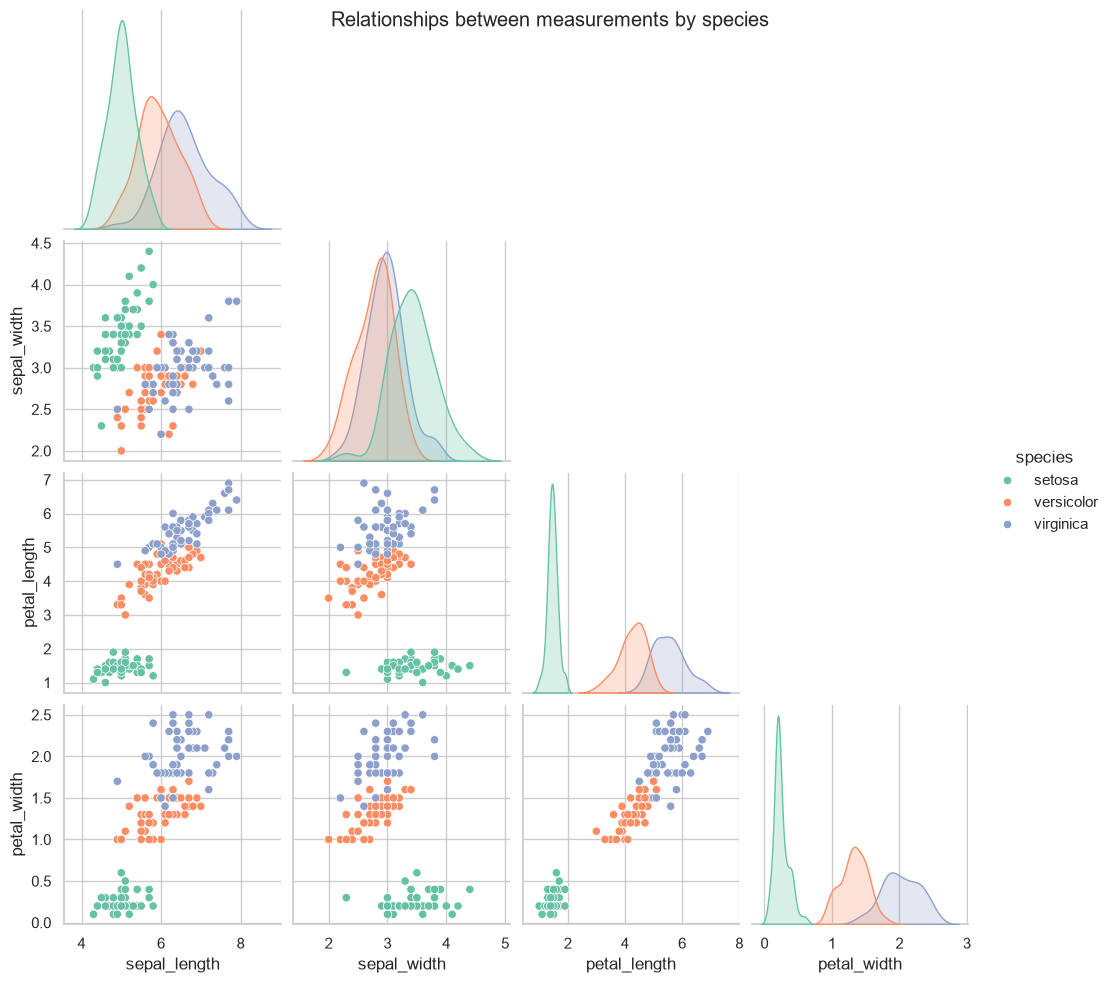

In [5]:
sns.pairplot(df.drop(columns="target"), hue="species", palette="Set2", corner=True)
plt.suptitle("Relationships between measurements by species")
plt.show()

There are obvious relationships among the measurements of flowers. The petal length and petal width are highly correlated and are the most significant attributes for differentiating the species. Setosa is well-separated from the other two species, whereas versicolor and virginica have overlapping regions. In general, the petals are more informative than the sepals for species differentiation.

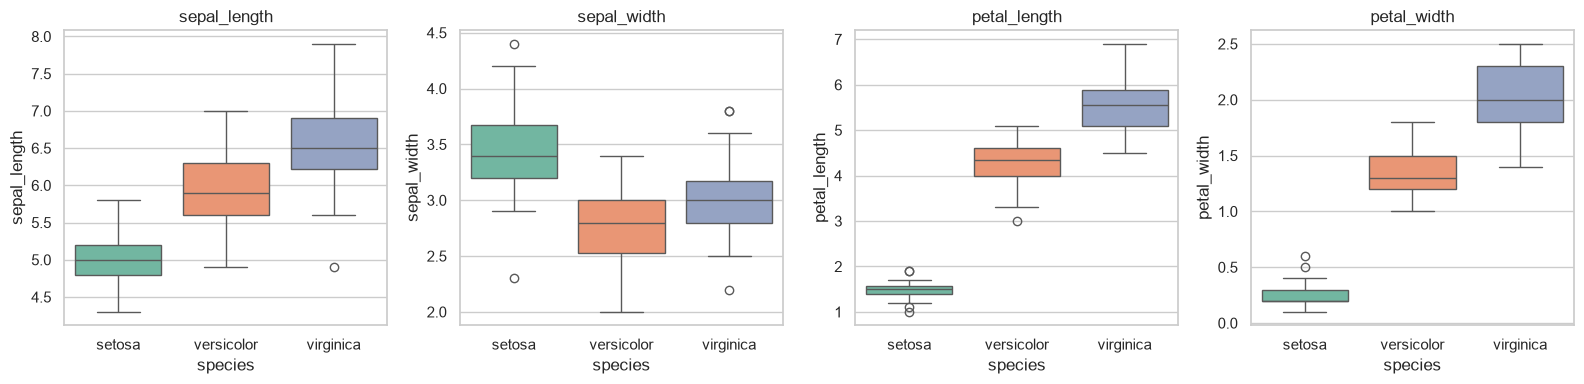

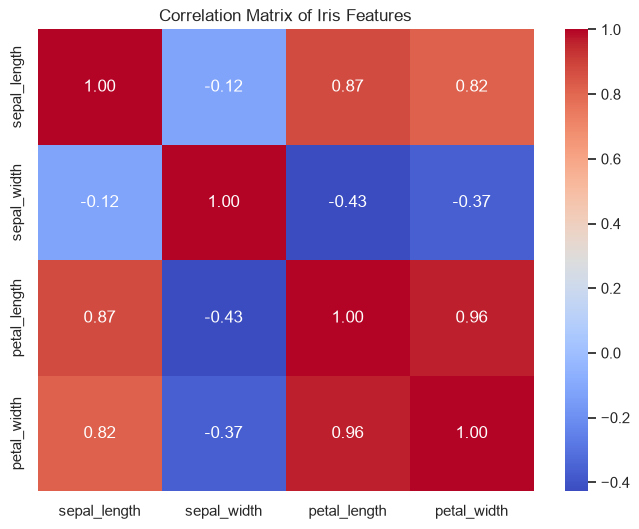

In [6]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, features):
    sns.boxplot(x="species", y=col,hue="species", data=df, ax=ax, palette="Set2", legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Iris Features")
plt.show()

**- Boxplots – Distribution of Features by Species**
The differences between each iris category are obvious in boxplots, especially concerning petal measurements. The setosa category has noticeably small petals, while the virginica has the largest ones. The versicolor category lies somewhere between both categories. In addition, there is a considerable degree of overlapping in sepal measurements of different categories. Also, there are outliers observed in some cases.

**- Correlation Matrix – Iris Features**
The correlation matrix shows an extremely high positive correlation between petal length and petal width (0.96). The correlation between sepal length and petal length (0.87) and petal width (0.82) is also high. In comparison to this, sepal width is moderately negatively correlated with petal measurements. This indicates that there is a high relationship between petal measurements.

## Step 5 : Data prep

- `X` = the 4 measurements (inputs), `y` = the species (what we want to predict).
- We split 80% of the flowers to **train** and 20% to **test**. The model never sees the test set during training, which lets us measure its true performance.
- `stratify=y` keeps the same proportion of species in both sets.

In [7]:
X = df[features]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train :", X_train.shape, "Test :", X_test.shape )

Train : (120, 4) Test : (30, 4)


## Step 6 : Training models
We compare 4 classic models. For those that depend on distances (KNN, logistic regression), we put the measures on the same scale with `StandardScaler`; the `pipeline` automatically chains scaling and then the model.

We also use **cross-validation** (5 different splits of the training set): the result is more reliable than a single test, especially with a small dataset of 150 rows.

In [9]:
from sklearn.model_selection import cross_val_score
models = {
    "KNN (k=5)" : make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Logistic Regression" : make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "Decision Tree" : DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest" : RandomForestClassifier(n_estimators=100,random_state=RANDOM_STATE),
}

rows=[]
for name, model in models.items():
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    rows.append({"Model" : name, "Accuracy CV (mean)":cv.mean(), "Standard deviation CV":cv.std(), "Test Accuracy":test_acc})
    
results = pd.DataFrame(rows).sort_values(by="Test Accuracy", ascending=False).reset_index(drop=True)
results.round(3)

,Model,Accuracy CV (mean),Standard deviation CV,Test Accuracy
0,KNN (k=5),0.967,0.031,0.933
1,Logistic Regression,0.958,0.026,0.933
2,Decision Tree,0.942,0.020,0.933
3,Random Forest,0.950,0.017,0.900


## Step 7 : Choosing the best model

In [10]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print(f"Best model: {best_name}")

Best model: KNN (k=5)


## Step 8 : Evaluate the chosen model

Accuracy :0.933

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



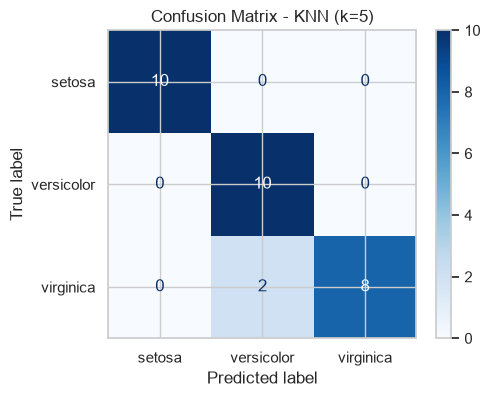

In [12]:
y_pred = best_model.predict(X_test)
print(f"Accuracy :{accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names, cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix - {best_name}")
plt.show()

The KNN model (k=5) achieves 93.3% accuracy, showing strong classification performance. Setosa is perfectly classified, while minor confusion occurs between versicolor and virginica. Overall, the model provides reliable classification results.

## Step 9 : predict a new flower

In [22]:
new_flower = pd.DataFrame([[5.0, 3.5, 1.5, 0.2]], columns=features)
predicted_class = best_model.predict(new_flower)[0]
print(f"The predicted species for the new flower is: {iris.target_names[predicted_class]}")
if hasattr(best_model, "predict_proba") :
    proba = best_model.predict_proba(new_flower)[0]
    print({n: round(float(p),2) for n,p in zip(iris.target_names, proba)})

The predicted species for the new flower is: setosa
{np.str_('setosa'): 1.0, np.str_('versicolor'): 0.0, np.str_('virginica'): 0.0}


# Conclusion
- The measurements of the **petals** are almost enough on their own to distinguish the species.
- The chosen model reaches a high accuracy (see table above). The few errors involve *versicolor* / *virginica*, which look alike.
- **Limitation:** the test set only contains 30 flowers, so a single misclassified example can change the score a lot. That’s why we also rely on cross-validation.
- **To go further:** tune the hyperparameters with `GridSearchCV`, or try other models (SVM).